In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix
)

plt.rcParams.update({
    'figure.facecolor': '#f8f9fa',
    'axes.facecolor':   '#ffffff',
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'font.size': 11,
})
COLORS = ['#4C72B0', '#DD8452', '#55A868']

print('All libraries imported successfully.')

All libraries imported successfully.


In [2]:
# ── Load ────────────────────────────────────────────────────────────────────
df = pd.read_csv('data/load_data.csv')
df.columns = df.columns.str.strip()

# Sanitize column names (dots -> underscores, spaces -> underscores)
df.columns = [c.replace('.', '_').replace(' ', '_') for c in df.columns]

# ── Parse timestamps & extract calendar features ─────────────────────────────
df['Date_Time'] = pd.to_datetime(df['Date_Time'], format='%d-%m-%Y %H:%M')
df = df.sort_values('Date_Time').reset_index(drop=True)

df['month']      = df['Date_Time'].dt.month
df['hour']       = df['Date_Time'].dt.hour
df['minute']     = df['Date_Time'].dt.minute
df['dayofweek']  = df['Date_Time'].dt.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)
df['date_only']  = df['Date_Time'].dt.date

# ── Physical sanity clipping ─────────────────────────────────────────────────
df = df.replace(r'^\s*$', np.nan, regex=True).ffill().bfill()
df['Lagging_Current_Power_Factor']  = df['Lagging_Current_Power_Factor'].astype(float).clip(0, 100)
df['Leading_Current_Power_Factor']  = df['Leading_Current_Power_Factor'].astype(float).clip(0, 100)
df['NSM'] = df['NSM'].astype(float).clip(0, 86400)

# ── Encode target label ───────────────────────────────────────────────────────
le = LabelEncoder()
df['Load_Type_enc'] = le.fit_transform(df['Load_Type'])

print(f'Dataset shape : {df.shape}')
print(f'Date range    : {df["Date_Time"].min()} -> {df["Date_Time"].max()}')
print(f'\nClass label mapping (alphabetical = LabelEncoder order):')
for i, cls in enumerate(le.classes_):
    print(f'  Class {i}  ->  {cls}')

Dataset shape : (35041, 16)
Date range    : 2018-01-01 00:00:00 -> 2018-12-31 23:45:00

Class label mapping (alphabetical = LabelEncoder order):
  Class 0  ->  Light_Load
  Class 1  ->  Maximum_Load
  Class 2  ->  Medium_Load


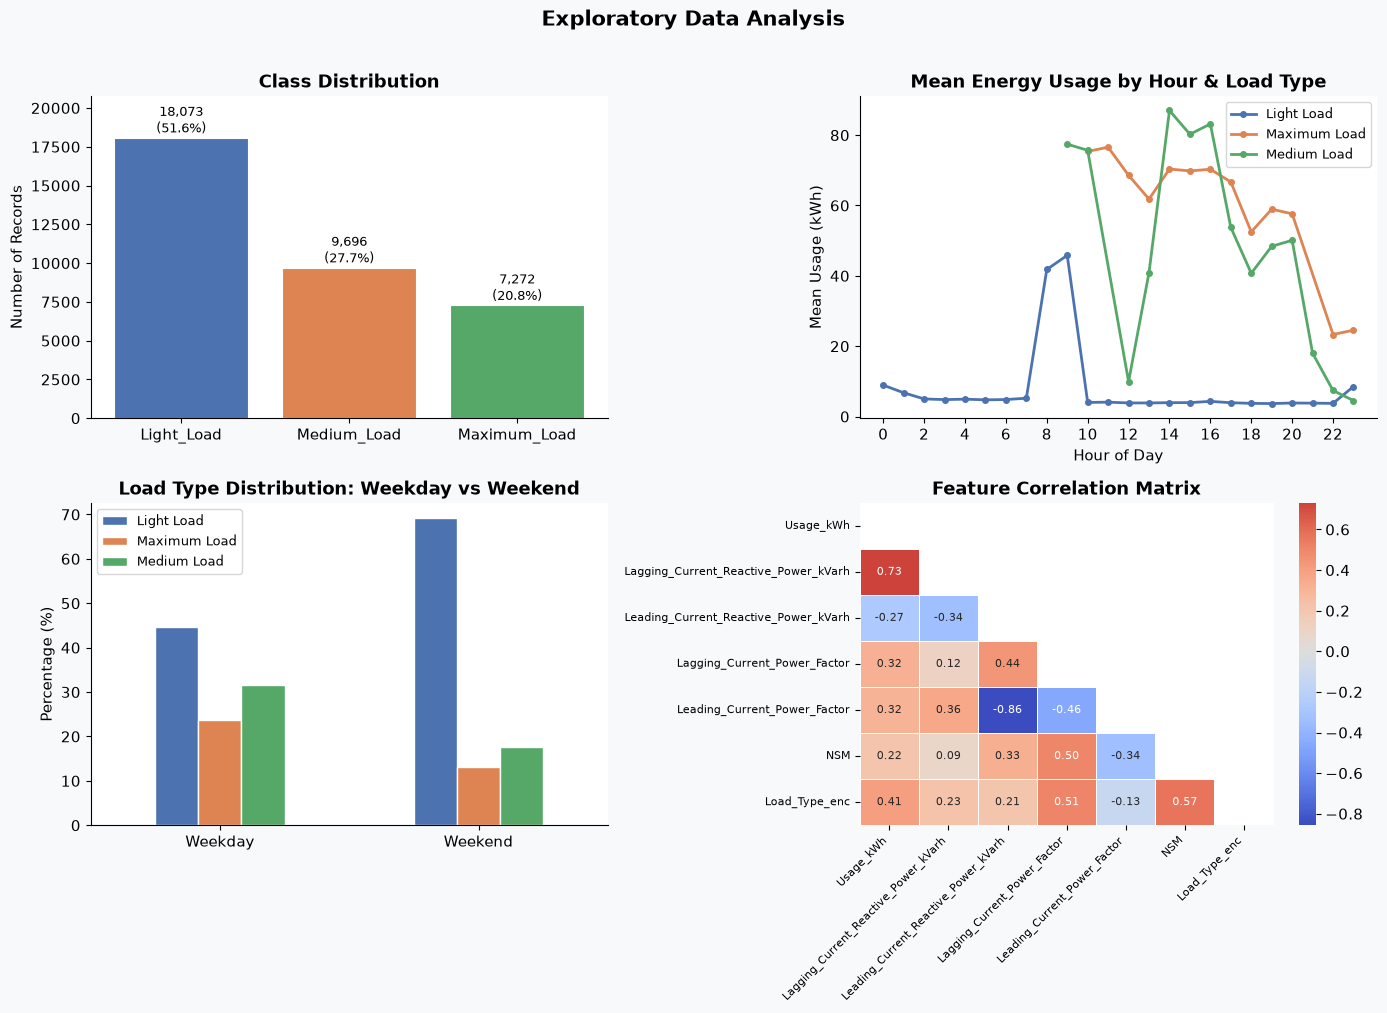

EDA complete.


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Exploratory Data Analysis', fontsize=15, fontweight='bold', y=1.01)

# ─ Plot 1: Class Distribution ───────────────────────────────────
ax = axes[0, 0]
counts = df['Load_Type'].value_counts()
bars = ax.bar(counts.index, counts.values, color=COLORS, edgecolor='white', linewidth=0.8)
ax.set_title('Class Distribution', fontweight='bold')
ax.set_ylabel('Number of Records')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
            f'{val:,}\n({val/len(df)*100:.1f}%)', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, counts.max() * 1.15)

# ─ Plot 2: Mean Usage_kWh by Hour and Load Type ────────────────────
ax = axes[0, 1]
hourly = df.groupby(['hour', 'Load_Type'])['Usage_kWh'].mean().reset_index()
for i, lt in enumerate(le.classes_):
    d = hourly[hourly['Load_Type'] == lt]
    ax.plot(d['hour'], d['Usage_kWh'], marker='o', markersize=4,
            label=lt.replace('_', ' '), color=COLORS[i], linewidth=2)
ax.set_title('Mean Energy Usage by Hour & Load Type', fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Mean Usage (kWh)')
ax.legend(fontsize=9)
ax.set_xticks(range(0, 24, 2))

# ─ Plot 3: Load Type by Weekday vs Weekend ───────────────────────
ax = axes[1, 0]
weekend_dist = df.groupby(['is_weekend', 'Load_Type']).size().unstack(fill_value=0)
weekend_dist.index = ['Weekday', 'Weekend']
weekend_pct = weekend_dist.div(weekend_dist.sum(axis=1), axis=0) * 100
weekend_pct.plot(kind='bar', ax=ax, color=COLORS, edgecolor='white', width=0.5)
ax.set_title('Load Type Distribution: Weekday vs Weekend', fontweight='bold')
ax.set_ylabel('Percentage (%)')
ax.set_xlabel('')
ax.set_xticklabels(['Weekday', 'Weekend'], rotation=0)
ax.legend([c.replace('_', ' ') for c in weekend_pct.columns], fontsize=9)

# ─ Plot 4: Correlation Heatmap ─────────────────────────────────
ax = axes[1, 1]
numeric_cols = ['Usage_kWh', 'Lagging_Current_Reactive_Power_kVarh',
                'Leading_Current_Reactive_Power_kVarh', 'CO2_tCO2_',
                'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor',
                'NSM', 'Load_Type_enc']
# Use whichever column names exist
existing = [c for c in numeric_cols if c in df.columns]
corr = df[existing].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Feature Correlation Matrix', fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=120, bbox_inches='tight')
plt.show()
print('EDA complete.')

In [ ]:
# ── A. Cyclical time encoding ───────────────────────────────────────────────
df['NSM_sin'] = np.sin(2 * np.pi * df['NSM'] / 86400)
df['NSM_cos'] = np.cos(2 * np.pi * df['NSM'] / 86400)

# ── B. Multi-scale lag features (all shifted >= 1 step = 15 min) ─────────────
df['Usage_lag1']  = df['Usage_kWh'].shift(1)   # 15 min ago
df['Usage_lag2']  = df['Usage_kWh'].shift(2)   # 30 min ago
df['Usage_lag4']  = df['Usage_kWh'].shift(4)   # 1 h ago
df['Usage_lag12'] = df['Usage_kWh'].shift(12)  # 3 h ago

# ── C. Velocity (momentum) ─────────────────────────────────────────────────
df['Usage_diff_1'] = df['Usage_lag1'] - df['Usage_lag2']

# ── D. Rolling volatility bounds (based on lag1 so no leakage) ────────────
df['Roll_mean_4']  = df['Usage_lag1'].rolling(window=4,  min_periods=1).mean()
df['Roll_max_12']  = df['Usage_lag1'].rolling(window=12, min_periods=1).max()
df['Roll_min_12']  = df['Usage_lag1'].rolling(window=12, min_periods=1).min()

# ── E. Physics proxy: apparent power from lagged values ───────────────────
lag_react_lag = df['Lagging_Current_Reactive_Power_kVarh'].shift(1)
lead_react_lag = df['Leading_Current_Reactive_Power_kVarh'].shift(1)
df['Apparent_Power_Lag'] = np.sqrt(
    df['Usage_lag1']**2 + lag_react_lag**2 + lead_react_lag**2
)
df['Reactive_Active_Ratio'] = lag_react_lag / (df['Usage_lag1'] + 0.001)

# ── F. Historical schedule profile ────────────────────────────────────────

# We assign an ISO week number and merge on week-1 to avoid self-contamination.
df['week'] = df['Date_Time'].dt.isocalendar().week.astype(int)

# Build profile table: mean Usage_kWh grouped by (dayofweek, hour, minute)
# using only months 1-10 (training months) → purely past data
profile_src = df[df['month'] <= 10].copy()
profile_map = (
    profile_src
    .groupby(['dayofweek', 'hour', 'minute'])['Usage_lag1']
    .mean()
    .reset_index()
    .rename(columns={'Usage_lag1': 'Hist_Expected_Usage'})
)
df = pd.merge(df, profile_map, on=['dayofweek', 'hour', 'minute'], how='left')
df['Hist_Expected_Usage']   = df['Hist_Expected_Usage'].fillna(df['Roll_mean_4'])
df['Usage_Dev_From_Profile'] = df['Usage_lag1'] - df['Hist_Expected_Usage']

# ── Drop rows with NaN from lags (first 12 rows) ─────────────────────────
df = df.dropna(subset=['Usage_lag12']).copy()

print(f'Feature engineering complete. Shape: {df.shape}')
print(f'Features engineered: NSM cyclical, 4 usage lags, velocity, rolling stats,'
      f' apparent power, reactive ratio, profile deviation')

Feature engineering complete. Shape: (35029, 31)
Features engineered: NSM cyclical, 4 usage lags, velocity, rolling stats, apparent power, reactive ratio, profile deviation


In [12]:
df

,Date_Time,Usage_kWh,Lagging_Current_Reactive_Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type,month,...,Usage_lag12,Usage_diff_1,Roll_mean_4,Roll_max_12,Roll_min_12,Apparent_Power_Lag,Reactive_Active_Ratio,week,Hist_Expected_Usage,Usage_Dev_From_Profile
12,2018-01-01 03:00:00,3.24,3.64,0.00,0.0,66.49,100.00,10800.000000,Light_Load,1,...,3.420000,-0.32,4.192654,8.753692,3.24,5.311544,1.164403,1,3.640287,-0.180287
13,2018-01-01 03:15:00,3.96,4.97,0.00,0.0,62.32,100.00,11700.000000,Light_Load,1,...,8.753692,-0.22,4.102654,8.753692,3.24,4.873110,1.123110,1,3.883774,-0.643774
14,2018-01-01 03:30:00,3.31,3.74,0.00,0.0,66.27,100.00,36574.178080,Light_Load,1,...,4.000000,0.72,3.610000,5.930615,3.24,6.354723,1.254734,1,3.583007,0.376993
15,2018-01-01 03:45:00,3.31,3.85,0.00,0.0,65.19,100.00,35294.963036,Light_Load,1,...,3.240000,-0.65,3.492500,5.930615,3.24,4.994367,1.129568,1,3.364981,-0.054981
16,2018-01-01 04:00:00,3.89,5.00,0.00,0.0,61.40,100.00,14400.000000,Light_Load,1,...,3.310000,0.00,3.455000,5.930615,3.24,5.077263,1.162791,1,3.472264,-0.162264
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35036,2018-12-31 22:45:00,3.82,4.54,0.00,0.0,64.38,100.00,81900.000000,Light_Load,12,...,11.361452,0.00,3.761332,11.361452,3.24,5.488397,1.366862,1,11.684395,-8.444395
35037,2018-12-31 23:00:00,3.85,4.86,0.00,0.0,62.10,100.00,82800.000000,Light_Load,12,...,4.140000,0.58,3.430000,9.442907,3.24,5.933296,1.188171,1,10.452244,-6.632244
35038,2018-12-31 23:15:00,3.74,3.74,0.00,0.0,70.71,100.00,83700.000000,Light_Load,12,...,4.180000,0.03,3.537500,9.442907,3.24,6.200169,1.262010,1,12.863868,-9.013868
35039,2018-12-31 23:30:00,3.78,3.17,0.07,0.0,76.62,99.98,86400.000000,Light_Load,12,...,9.442907,-0.11,3.662500,9.442907,3.24,5.289159,0.999733,1,10.112943,-6.372943


In [5]:
# Feature set: current-step Usage_kWh and CO2 excluded (leaky)
FEATURES = [
    # Power factor readings (instantaneous, but assignment-listed features)
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    # Cyclical time
    'NSM_sin', 'NSM_cos',
    # Calendar
    'hour', 'dayofweek', 'is_weekend',
    # Lag-based usage history
    'Usage_lag1', 'Usage_lag2', 'Usage_lag4', 'Usage_lag12',
    # Momentum & volatility
    'Usage_diff_1', 'Roll_mean_4', 'Roll_max_12', 'Roll_min_12',
    # Physics proxies (all lagged)
    'Apparent_Power_Lag', 'Reactive_Active_Ratio',
    # Historical schedule deviation
    'Hist_Expected_Usage', 'Usage_Dev_From_Profile',
]

train_df = df[df['month'] <= 10].copy()   # Jan-Oct
val_df   = df[df['month'] == 11].copy()   # November  <- calibration tuning
test_df  = df[df['month'] == 12].copy()   # December  <- final blind test

X_train, y_train = train_df[FEATURES], train_df['Load_Type_enc']
X_val,   y_val   = val_df[FEATURES],   val_df['Load_Type_enc']
X_test,  y_test  = test_df[FEATURES],  test_df['Load_Type_enc']

print(f'Train  (Jan-Oct) : {X_train.shape}')
print(f'Val    (Nov)     : {X_val.shape}')
print(f'Test   (Dec)     : {X_test.shape}')
print(f'\nTarget distribution in train:')
for i, cls in enumerate(le.classes_):
    n = (y_train == i).sum()
    print(f'  {cls}: {n} ({n/len(y_train)*100:.1f}%)')

Train  (Jan-Oct) : (29172, 19)
Val    (Nov)     : (2880, 19)
Test   (Dec)     : (2977, 19)

Target distribution in train:
  Light_Load: 14948 (51.2%)
  Maximum_Load: 6096 (20.9%)
  Medium_Load: 8128 (27.9%)


In [6]:
# Scale features for logistic regression
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

# Fit baseline
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(X_train_sc, y_train)

lr_val_preds  = lr.predict(X_val_sc)
lr_test_preds = lr.predict(X_test_sc)

lr_val_acc  = accuracy_score(y_val,  lr_val_preds)
lr_test_acc = accuracy_score(y_test, lr_test_preds)

print('=' * 55)
print('BASELINE: Logistic Regression')
print('=' * 55)
print(f'Validation Accuracy (Nov) : {lr_val_acc * 100:.2f}%')
print(f'Test Accuracy      (Dec)  : {lr_test_acc * 100:.2f}%')
print()
print('Test Classification Report:')
print(classification_report(
    le.inverse_transform(y_test),
    le.inverse_transform(lr_test_preds)
))

BASELINE: Logistic Regression
Validation Accuracy (Nov) : 66.25%
Test Accuracy      (Dec)  : 66.11%

Test Classification Report:
              precision    recall  f1-score   support

  Light_Load       0.98      0.83      0.90      1745
Maximum_Load       0.35      0.43      0.39       528
 Medium_Load       0.33      0.40      0.37       704

    accuracy                           0.66      2977
   macro avg       0.56      0.56      0.55      2977
weighted avg       0.72      0.66      0.68      2977



In [7]:
custom_weights = {0: 1.0, 1: 1.6, 2: 1.4}   # Light / Maximum / Medium

# ── LightGBM ────────────────────────────────────────────────────────────────
model_lgb = LGBMClassifier(
    n_estimators=600,
    learning_rate=0.012,
    max_depth=9,
    num_leaves=127,
    min_child_samples=35,
    class_weight=custom_weights,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# ── XGBoost ────────────────────────────────────────────────────────────────
sample_weights_train = y_train.map(custom_weights)

model_xgb = XGBClassifier(
    n_estimators=600,
    learning_rate=0.012,
    max_depth=7,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

print('Training LightGBM...')
model_lgb.fit(X_train, y_train)

print('Training XGBoost...')
model_xgb.fit(X_train, y_train, sample_weight=sample_weights_train)

# ── Soft probability ensemble (val + test) ─────────────────────────────
probs_lgb_val  = model_lgb.predict_proba(X_val)
probs_xgb_val  = model_xgb.predict_proba(X_val)
final_probs_val = (probs_lgb_val * 0.4) + (probs_xgb_val * 0.6)

probs_lgb_test  = model_lgb.predict_proba(X_test)
probs_xgb_test  = model_xgb.predict_proba(X_test)
final_probs_test = (probs_lgb_test * 0.4) + (probs_xgb_test * 0.6)

raw_val_acc  = accuracy_score(y_val,  np.argmax(final_probs_val, axis=1))
raw_test_acc = accuracy_score(y_test, np.argmax(final_probs_test, axis=1))
print(f'\nRaw ensemble (no calibration):')
print(f'  Validation Accuracy (Nov) : {raw_val_acc * 100:.2f}%')
print(f'  Test Accuracy      (Dec)  : {raw_test_acc * 100:.2f}%')
print('Models trained.')

Training LightGBM...
Training XGBoost...

Raw ensemble (no calibration):
  Validation Accuracy (Nov) : 71.04%
  Test Accuracy      (Dec)  : 76.76%
Models trained.


In [8]:
def apply_calibration(probs, w_max, w_med):
    """Multiplicative probability scaling.
    Class indices: 0=Light_Load, 1=Maximum_Load, 2=Medium_Load (alphabetical LabelEncoder order)
    """
    p = probs.copy()
    p[:, 1] *= w_max   # Maximum_Load
    p[:, 2] *= w_med   # Medium_Load
    return np.argmax(p, axis=1)

# ── Grid search on VALIDATION SET (November) ONLY ────────────────────────
best_val_acc  = 0.0
best_w_max    = 1.0
best_w_med    = 1.0

for w_max in np.linspace(0.8, 1.8, 11):
    for w_med in np.linspace(0.7, 1.3, 7):
        preds = apply_calibration(final_probs_val, w_max, w_med)
        acc   = accuracy_score(y_val, preds)
        if acc > best_val_acc:
            best_val_acc = acc
            best_w_max   = w_max
            best_w_med   = w_med

print(f'Calibration tuned on November (validation set):')
print(f'  Best w_max (Maximum_Load) : {best_w_max:.2f}')
print(f'  Best w_med (Medium_Load)  : {best_w_med:.2f}')
print(f'  November validation acc   : {best_val_acc * 100:.2f}%')

# ── Apply chosen weights ONCE to December (blind test) ───────────────────
final_preds = apply_calibration(final_probs_test, best_w_max, best_w_med)
final_acc   = accuracy_score(y_test, final_preds)

print(f'\nDecember blind-test accuracy (calibrated): {final_acc * 100:.2f}%')

Calibration tuned on November (validation set):
  Best w_max (Maximum_Load) : 1.70
  Best w_med (Medium_Load)  : 0.70
  November validation acc   : 72.33%

December blind-test accuracy (calibrated): 78.07%


In [9]:
y_test_labels = le.inverse_transform(y_test)
y_pred_labels = le.inverse_transform(final_preds)
lr_test_labels = le.inverse_transform(lr_test_preds)

# ── Summary comparison table ─────────────────────────────────────────────
from sklearn.metrics import f1_score

models = {
    'Logistic Regression (baseline)': (lr_test_preds, lr_test_labels),
    'LightGBM + XGBoost Ensemble (calibrated)': (final_preds, y_pred_labels),
}

print('=' * 62)
print(f'{"Model":<42} {"Accuracy":>9} {"Macro-F1":>9}')
print('=' * 62)
for name, (preds_enc, preds_lbl) in models.items():
    acc = accuracy_score(y_test, preds_enc)
    f1  = f1_score(y_test, preds_enc, average='macro')
    print(f'{name:<42} {acc*100:>8.2f}% {f1:>9.3f}')
print('=' * 62)

print()
print('--- Full Report: LightGBM + XGBoost Ensemble ---')
print(classification_report(y_test_labels, y_pred_labels))

Model                                       Accuracy  Macro-F1
Logistic Regression (baseline)                66.11%     0.553
LightGBM + XGBoost Ensemble (calibrated)      78.07%     0.669

--- Full Report: LightGBM + XGBoost Ensemble ---
              precision    recall  f1-score   support

  Light_Load       0.99      0.95      0.97      1745
Maximum_Load       0.46      0.51      0.48       528
 Medium_Load       0.55      0.55      0.55       704

    accuracy                           0.78      2977
   macro avg       0.67      0.67      0.67      2977
weighted avg       0.79      0.78      0.79      2977



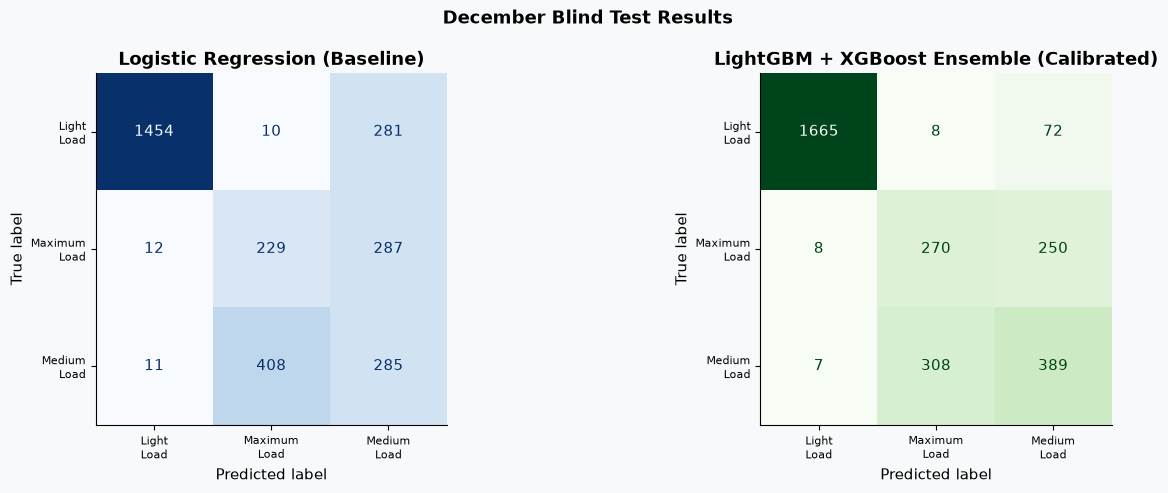

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('December Blind Test Results', fontsize=13, fontweight='bold')

# ─ Confusion matrix: Baseline ─────────────────────────────────────────
cm_lr = confusion_matrix(y_test_labels, lr_test_labels, labels=le.classes_)
disp_lr = ConfusionMatrixDisplay(cm_lr, display_labels=le.classes_)
disp_lr.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Logistic Regression (Baseline)', fontweight='bold')
axes[0].set_xticklabels([c.replace('_', '\n') for c in le.classes_], fontsize=8)
axes[0].set_yticklabels([c.replace('_', '\n') for c in le.classes_], fontsize=8)

# ─ Confusion matrix: Ensemble ─────────────────────────────────────────
cm_ens = confusion_matrix(y_test_labels, y_pred_labels, labels=le.classes_)
disp_ens = ConfusionMatrixDisplay(cm_ens, display_labels=le.classes_)
disp_ens.plot(ax=axes[1], colorbar=False, cmap='Greens')
axes[1].set_title('LightGBM + XGBoost Ensemble (Calibrated)', fontweight='bold')
axes[1].set_xticklabels([c.replace('_', '\n') for c in le.classes_], fontsize=8)
axes[1].set_yticklabels([c.replace('_', '\n') for c in le.classes_], fontsize=8)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

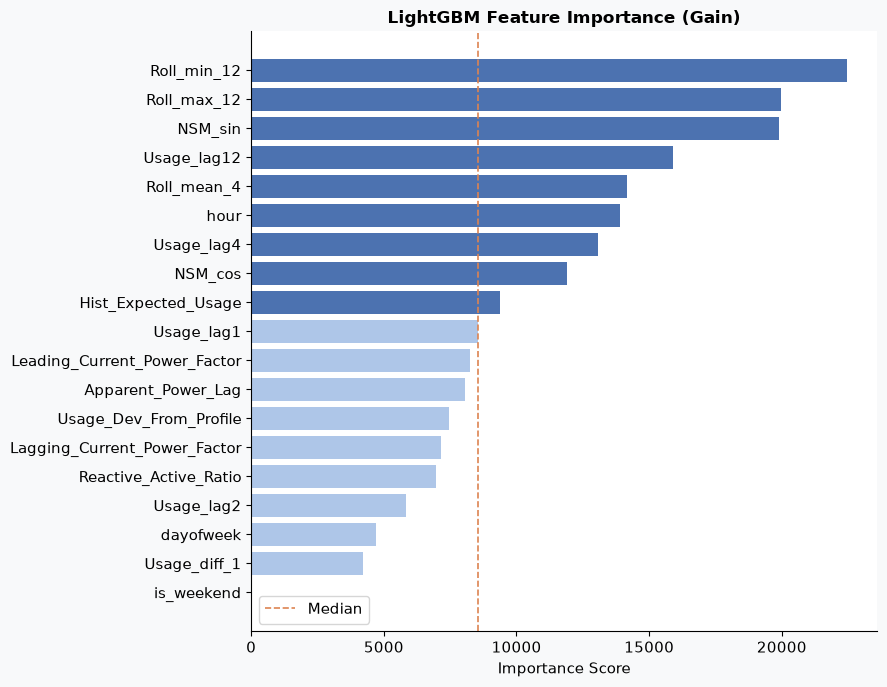

In [11]:
# ── Feature Importance from LightGBM ───────────────────────────────────────
importances = pd.Series(model_lgb.feature_importances_, index=FEATURES).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(importances.index, importances.values,
               color=['#4C72B0' if v > importances.median() else '#AEC6E8'
                      for v in importances.values])
ax.set_title('LightGBM Feature Importance (Gain)', fontweight='bold', fontsize=12)
ax.set_xlabel('Importance Score')
ax.axvline(importances.median(), color='#DD8452', linestyle='--', linewidth=1.2, label='Median')
ax.legend()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()